# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Программные средства сбора, консолидации и аналитики данных»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Программа:** «Бизнес-аналитика и большие данные»  
**Тема:** 1. Программные средства сбора данных  
**Формат:** интерактивный ноутбук Google Colab · **максимум 10 баллов** · срок сдачи — в Moodle (EnvLab)

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» значения регулярными выражениями (числа, цены, остатки, даты; зарплаты и навыки — если они присутствуют в данных вашего варианта).
4. Подготовить таблицы `pandas` для API и HTML-данных, проверить качество, провести разведочный анализ и построить **не менее четырёх графиков** по варианту.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**. Она различает **✅ выполнено**, **❌ требует исправления**, **➖ не применяется** и **⚠ требует обоснования**. Число применимых проверок зависит от варианта; все применимые требования должны быть выполнены.
6. Если источник объективно предоставляет меньше 50 API-записей или 40 HTML-объектов, заполните пояснение непосредственно в ячейке самопроверки и в выводах. Самопроверка пометит этот пункт как требующий проверки преподавателем. Дублировать данные и подменять исходный вариант нельзя.
7. Номер варианта, показанный при первом открытии ноутбука, — **пример настройки**, а не назначение студенту. Выберите выданный преподавателем вариант.

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — исходный учебный ориентир, не универсальное разрешение на такую частоту. Соблюдайте ограничения API, `Retry-After`, правила сайта и при необходимости увеличивайте паузу.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Учебные или синтетические данные нельзя представлять как фактические рыночные результаты**; пометьте их источник и ограничения и повторите сбор, когда исходный ресурс станет доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [1]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 22              #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "OvsepyanMV746@mgpu.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.13.18 | requests 2.32.4 | bs4 4.13.5 | lxml 6.1.3 | pandas 2.2.3 | seaborn 0.13.2
Вариант: 22 | кэш: /content/pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Для публичных ресурсов ориентируйтесь на опубликованные ограничения и ответ сервера; при необходимости увеличьте паузу и обрабатывайте `429`/`Retry-After`.

In [2]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 22 — Финтех
Бизнес-задача: Волатильность рубля как фактор ценообразования

Источник API : cbr.ru — курсы валют ЦБ РФ (XML, без ключа)
Параметры API: {'currencies': ['USD', 'EUR'], 'days': 365}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'business_35', 'pages': 3}

Метрики и визуализации:
  Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [7]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
import shutil

TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}

# Очистка кэша, чтобы применить исправленный парсинг и скачать XML заново
shutil.rmtree(CACHE_DIR, ignore_errors=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ TODO 2.1
def fetch_api(cfg):
    """Сбор курсов валют ЦБ РФ за N дней до сегодняшнего дня."""
    source = cfg["api"]
    params = cfg["api_params"]

    if source != "cbr":
        raise NotImplementedError(f"Источник {source} не поддержан в этой версии")

    days = int(params.get("days", 90))
    currencies = params.get("currencies", ["USD"])
    date_req2 = datetime.now().date()
    date_req1 = date_req2 - timedelta(days=days)

    raw = []
    for code in currencies:
        val_nm_rq = CBR_CODES.get(code)
        if val_nm_rq is None:
            print(f"[WARN] {code}: нет кода ЦБ РФ, пропускаю")
            continue

        req_params = {
            "date_req1": date_req1.strftime("%d/%m/%Y"),
            "date_req2": date_req2.strftime("%d/%m/%Y"),
            "VAL_NM_RQ": val_nm_rq,
        }
        xml_text, meta = polite_get(CBR_DYNAMIC_URL, params=req_params, expect="xml")

        if xml_text is None:
            print(f"[ERROR] {code}: ошибка загрузки - {meta.get('error')}")
            continue

        try:
            tree = lxml_etree.fromstring(xml_text.encode("utf-8"))
        except Exception as e:
            print(f"[ERROR] {code}: не удалось разобрать XML - {e}")
            continue

        records = tree.xpath("//Record")
        for rec in records:
            # Извлекаем текст из вложенных тегов Nominal и Value
            nominal_el = rec.find("Nominal")
            value_el = rec.find("Value")

            nominal = int(nominal_el.text) if nominal_el is not None else 1
            value = value_el.text if value_el is not None else None

            raw.append({
                "date": rec.get("Date"),
                "currency": code,
                "nominal": nominal,
                "value": value,
            })

        print(f"  {code}: собрано {len(records)} записей "
              f"({req_params['date_req1']} -> {req_params['date_req2']})")

    print(f"Всего собрано: {len(raw)} сырых записей")
    return raw


# ------------------------------------------------------------------ TODO 2.2
def normalize_api(raw, source):
    """Приведение к плоскому DataFrame: date, currency, nominal, rate."""
    if not raw:
        return []

    rows = []
    for item in raw:
        try:
            d = pd.to_datetime(item["date"], format="%d.%m.%Y", errors="coerce")
        except Exception:
            d = pd.NaT

        nominal = item.get("nominal") or 1
        val_str = item.get("value")

        try:
            # Очищаем от пробелов и меняем запятую на точку
            if val_str is None or str(val_str).strip() == "":
                rate = np.nan
            else:
                rate_raw = float(str(val_str).replace(" ", "").replace(",", "."))
                rate = rate_raw / nominal
        except (TypeError, ValueError):
            rate = np.nan

        rows.append({
            "date": d,
            "currency": item["currency"],
            "nominal": nominal,
            "rate": rate,
        })
    return rows


raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
print(f"Собрано записей: {len(df_api)}")
display(df_api.head())

  USD: собрано 248 записей (12/11/2025 -> 12/11/2026)
  EUR: собрано 248 записей (12/11/2025 -> 12/11/2026)
Всего собрано: 496 сырых записей
Ключи первой записи: ['currency', 'date', 'nominal', 'value']
Собрано записей: 496


,date,currency,nominal,rate
0,2025-11-12,USD,1,81.3562
1,2025-11-13,USD,1,81.2852
2,2025-11-14,USD,1,80.6010
3,2025-11-15,USD,1,81.1276
4,2025-11-18,USD,1,81.1302


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если используется аварийный, офлайн- или синтетический набор данных, явно обозначьте это в ноутбуке. Такой набор подходит для отладки, но не подтверждает выводы о состоянии реального рынка.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [15]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
}

def parse_with_bs4(html, site):
    soup = BeautifulSoup(html, "html.parser")
    items = soup.select(site["item_css"])
    rows = []

    for item in items:
        row = {}
        for field, (selector, attr_type) in site["fields_css"].items():
            el = item.select_one(selector)
            if el is None:
                row[field] = None
            elif attr_type == "text":
                row[field] = el.get_text(" ", strip=True)
            elif attr_type == "class":
                row[field] = " ".join(el.get("class", []))
            else:
                row[field] = el.get(attr_type)
        rows.append(row)
    return rows

def parse_with_xpath(html, site):
    tree = lxml_html.fromstring(html)
    items = tree.xpath(site["item_xpath"])
    rows = []

    for item in items:
        row = {}
        for field, xpath_expr in site["fields_xpath"].items():
            res = item.xpath(xpath_expr)
            if not res:
                row[field] = None
            else:
                if isinstance(res, list):
                    val = " ".join(str(x).strip() for x in res if str(x).strip())
                    row[field] = val if val else None
                else:
                    row[field] = str(res).strip()
        rows.append(row)
    return rows

def collect_site(site, pages=3, **site_params):
    rows_bs4 = []
    rows_xpath = []
    target_count = 100
    p = 1

    while len(rows_bs4) < target_count and p <= pages + 5:
        url = site["page_url"](p, **site_params)
        html, meta = polite_get(url, expect="text")

        if html is None:
            if "404" in str(meta.get("error")):
                break
            p += 1
            continue

        bs4_rows = parse_with_bs4(html, site)
        xpath_rows = parse_with_xpath(html, site)

        if not bs4_rows:
            break

        rows_bs4.extend(bs4_rows)
        rows_xpath.extend(xpath_rows)
        p += 1

    return rows_bs4, rows_xpath

site_conf = SITES[CFG["site"]]
rows_bs4, rows_xpath = collect_site(site_conf, **CFG["site_params"])

# Добираем из science_22
if len(rows_bs4) < 40:
    extra_params = dict(CFG["site_params"])
    extra_params["category"] = "science_22"
    extra_rows_bs4, extra_rows_xpath = collect_site(site_conf, **extra_params)
    rows_bs4.extend(extra_rows_bs4)
    rows_xpath.extend(extra_rows_xpath)

# Добираем из travel_2
if len(rows_bs4) < 40:
    extra_params = dict(CFG["site_params"])
    extra_params["category"] = "travel_2"
    extra_rows_bs4, extra_rows_xpath = collect_site(site_conf, **extra_params)
    rows_bs4.extend(extra_rows_bs4)
    rows_xpath.extend(extra_rows_xpath)

# Добираем из fiction_10
if len(rows_bs4) < 40:
    extra_params = dict(CFG["site_params"])
    extra_params["category"] = "fiction_10"
    extra_rows_bs4, extra_rows_xpath = collect_site(site_conf, **extra_params)
    rows_bs4.extend(extra_rows_bs4)
    rows_xpath.extend(extra_rows_xpath)

df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]

titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")
display(df_web.head())

Карточек: 102 | совпадение BS4 и XPath: 102 из 102


,title,price_text,availability_text,rating_class,url
0,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,In stock,star-rating Four,../../../the-dirty-little-secrets-of-getting-y...
1,The Third Wave: An Entrepreneurâs Vision of ...,Â£12.61,In stock,star-rating Five,../../../the-third-wave-an-entrepreneurs-visio...
2,The 10% Entrepreneur: Live Your Startup Dream ...,Â£27.55,In stock,star-rating Three,../../../the-10-entrepreneur-live-your-startup...
3,Shoe Dog: A Memoir by the Creator of NIKE,Â£23.99,In stock,star-rating Two,../../../shoe-dog-a-memoir-by-the-creator-of-n...
4,Made to Stick: Why Some Ideas Survive and Othe...,Â£38.85,In stock,star-rating Five,../../../made-to-stick-why-some-ideas-survive-...


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Количество объектов зависит от выбранного сайта, фильтра и числа страниц: оно не обязано равняться 20 на каждой странице. Если целая колонка заполнена `None`, проверьте селектор и наличие поля в фактической разметке.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [17]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "\u00a0\u202f\u2009"

def parse_price(text):
    """Извлекает цену из строки (убирает £, пробелы, меняет запятую на точку)"""
    if not text:
        return None
    match = re.search(r'(?P<num>\d{1,3}(?:[ \u00a0]\d{3})*(?:[.,]\d{1,2})?)', str(text))
    if match:
        num_str = match.group("num").replace(" ", "").replace("\u00a0", "").replace(",", ".")
        return float(num_str)
    return None

def parse_stock(text):
    """Извлекает число из 'In stock (22 available)'. Возвращает 0 для 'Out of stock'"""
    if not text:
        return 0
    text = str(text)
    if "Out of stock" in text:
        return 0
    match = re.search(r'\((\d+)\s*available\)', text)
    return int(match.group(1)) if match else 0

def parse_rating(class_text):
    """Извлекает рейтинг из класса 'star-rating Three' -> 3"""
    if not class_text:
        return None
    text = str(class_text)
    mapping = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
    for word, val in mapping.items():
        if word in text:
            return val
    return None

def parse_salary(text):
    """'от 60 000 до 90 000 руб.' -> (60000.0, 90000.0)"""
    if not text:
        return (None, None)
    text = str(text).lower().replace(NBSP, " ")
    min_val, max_val = None, None

    match_min = re.search(r'от\s*(\d[\d\s]*)', text)
    if match_min:
        min_val = float(match_min.group(1).replace(" ", ""))

    match_max = re.search(r'до\s*(\d[\d\s]*)', text)
    if match_max:
        max_val = float(match_max.group(1).replace(" ", ""))

    if min_val is None and max_val is None:
        matches = re.findall(r'\d[\d\s]*', text)
        if matches:
            vals = [float(m.replace(" ", "")) for m in matches if m.strip()]
            if len(vals) == 1:
                min_val, max_val = vals[0], vals[0]
            elif len(vals) >= 2:
                min_val, max_val = vals[0], vals[1]
    return (min_val, max_val)

def extract_skills(text):
    """Находит технологии в тексте"""
    if not text:
        return []
    text = str(text).lower()
    found = []
    for skill in SKILLS:
        if re.search(rf'(?<![\w]){re.escape(skill)}(?![\w])', text):
            found.append(skill)

    final_skills = []
    for s in found:
        if not any(s != other and s in other.split() for other in found):
            final_skills.append(s)

    return sorted(list(set(final_skills)))

def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()

def parse_date(text):
    """Парсит дату из '2026-03-15' или '15.03.2026'"""
    if not text:
        return pd.NaT
    text = str(text)
    if re.match(r'^\d{2}[.\-/]\d{2}[.\-/]\d{4}$', text):
        return pd.to_datetime(text, format="%d.%m.%Y", errors="coerce")
    return pd.to_datetime(text, errors="coerce")

SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]

REGEX_TESTS_OK = False
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) -> {got!r}, ожидалось {expected!r}"
REGEX_TESTS_OK = True
print("Регулярные выражения прошли проверку")

# ------------------------------------------------------------------ TODO 4.7: примените к данным
# Применяем функции к DataFrame df_web (книги)
if not df_web.empty:
    df_web["price"] = df_web["price_text"].apply(parse_price)
    df_web["stock"] = df_web["availability_text"].apply(parse_stock)
    df_web["rating"] = df_web["rating_class"].apply(parse_rating)

    # Проверяем качество распознавания
    print(f"Распознано цен: {df_web['price'].notna().sum()} из {len(df_web)}")
    print(f"Распознано остатков: {df_web['stock'].notna().sum()} из {len(df_web)}")
    print(f"Распознано рейтингов: {df_web['rating'].notna().sum()} из {len(df_web)}")

# Применяем функции к df_api (валюты), если нужно
if not df_api.empty:
    # В df_api колонка date уже спарсена при загрузке, но можем убедиться
    pass

Регулярные выражения прошли проверку
Распознано цен: 102 из 102
Распознано остатков: 102 из 102
Распознано рейтингов: 102 из 102


**Как читать вывод.** Сначала убедитесь, что тесты общих RegEx-функций выполнены: это часть задания для **всех вариантов**. Затем оцените качество очистки **применимых** полей в своём источнике. Для присутствующих и подлежащих извлечению значений ориентир — не менее 80% корректного распознавания. Отсутствие поля «зарплата» у GitHub, курсов валют, погоды и научных публикаций не является ошибкой: не добавляйте несуществующие показатели. Неудачные преобразования сохраняйте как пропуски и объясняйте их долю.


### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

In [19]:
#@title Шаг 5.0. Подготовка данных для графиков { display-mode: "form" }
import matplotlib.dates as mdates

# Подготовка курсов
df_currency = df_api.pivot(index="date", columns="currency", values="rate").dropna().sort_index()

# Доходности и волатильность
df_returns = df_currency.pct_change()
df_volatility = df_returns.rolling(window=30).std() * np.sqrt(252) * 100

# Перевод цен книг в рубли
avg_price_gbp = df_web["price"].mean()
last_usd_rate = df_currency["USD"].iloc[-1]
base_price_rub = avg_price_gbp * last_usd_rate

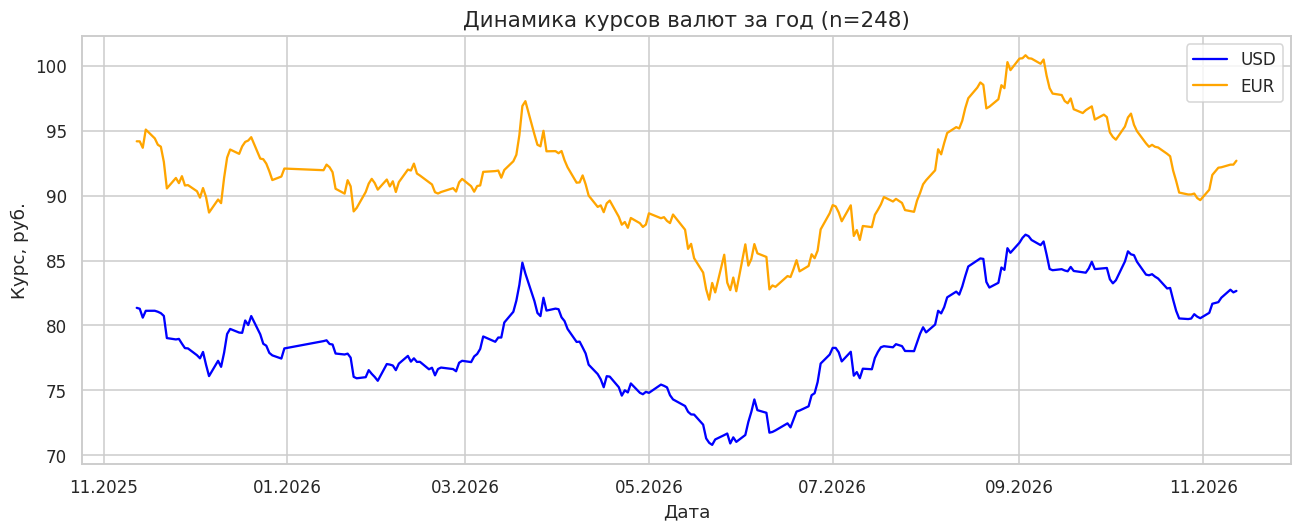

In [21]:
#@title График 1. Динамика курсов USD и EUR { display-mode: "form" }
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_currency, x="date", y="USD", label="USD", color="blue", linewidth=1.5)
sns.lineplot(data=df_currency, x="date", y="EUR", label="EUR", color="orange", linewidth=1.5)

plt.title(f"Динамика курсов валют за год (n={len(df_currency)})", fontsize=14)
plt.ylabel("Курс, руб.")
plt.xlabel("Дата")
plt.legend()
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
plt.tight_layout()
plt.show()

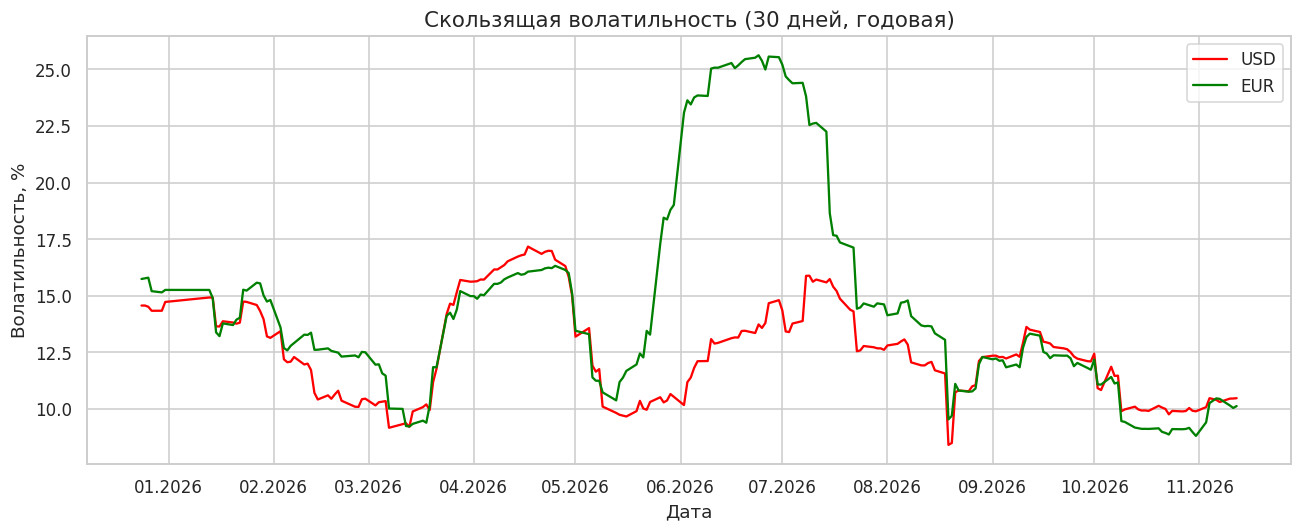

In [22]:
#@title График 2. Скользящая волатильность (30 дней) { display-mode: "form" }
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_volatility, x="date", y="USD", label="USD", color="red", linewidth=1.5)
sns.lineplot(data=df_volatility, x="date", y="EUR", label="EUR", color="green", linewidth=1.5)

plt.title("Скользящая волатильность (30 дней, годовая)", fontsize=14)
plt.ylabel("Волатильность, %")
plt.xlabel("Дата")
plt.legend()
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
plt.tight_layout()
plt.show()

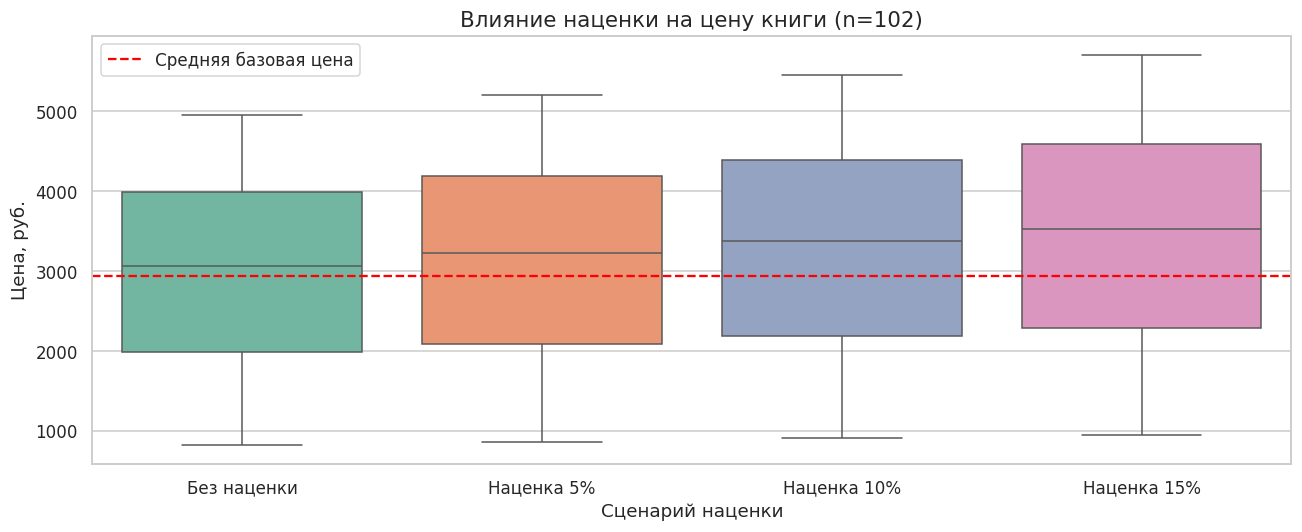

In [23]:
#@title График 3. Влияние наценки на цену книги { display-mode: "form" }
# Моделируем цены в рублях с разными наценками
scenarios = pd.DataFrame({
    "Без наценки": df_web["price"] * last_usd_rate,
    "Наценка 5%": df_web["price"] * last_usd_rate * 1.05,
    "Наценка 10%": df_web["price"] * last_usd_rate * 1.10,
    "Наценка 15%": df_web["price"] * last_usd_rate * 1.15,
})

plt.figure(figsize=(12, 5))
sns.boxplot(data=scenarios, palette="Set2", legend=False)

plt.title(f"Влияние наценки на цену книги (n={len(df_web)})", fontsize=14)
plt.ylabel("Цена, руб.")
plt.xlabel("Сценарий наценки")
plt.axhline(base_price_rub, color="red", linestyle="--", label="Средняя базовая цена")
plt.legend()
plt.tight_layout()
plt.show()

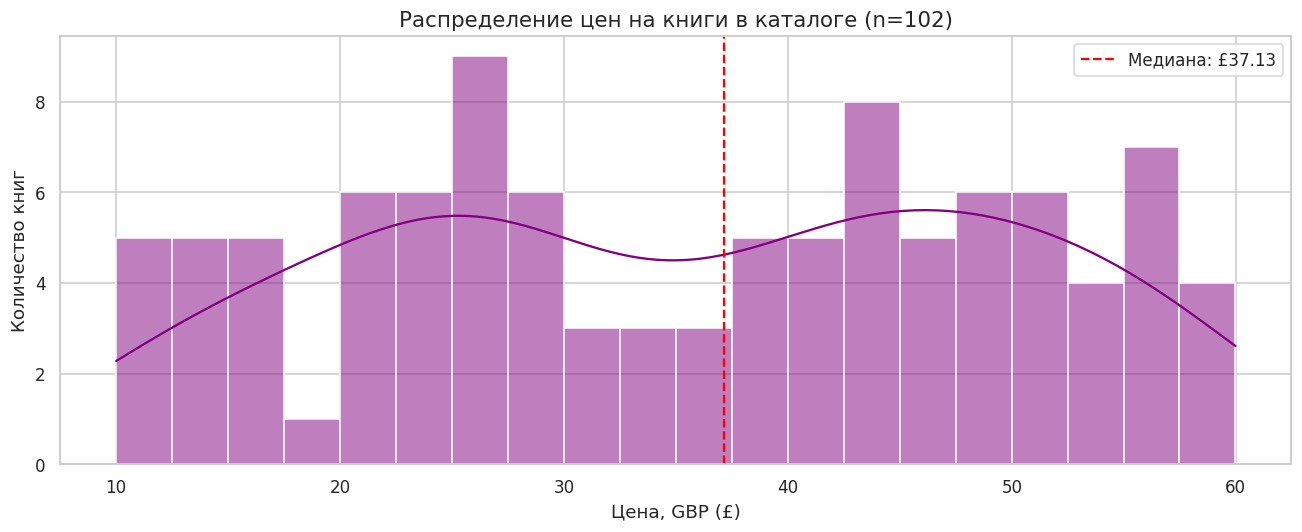

In [24]:
#@title График 4. Распределение цен на книги { display-mode: "form" }
plt.figure(figsize=(12, 5))
sns.histplot(df_web["price"], bins=20, kde=True, color="purple")

median_price = df_web["price"].median()
plt.axvline(median_price, color="red", linestyle="--", label=f"Медиана: £{median_price:.2f}")

plt.title(f"Распределение цен на книги в каталоге (n={len(df_web)})", fontsize=14)
plt.ylabel("Количество книг")
plt.xlabel("Цена, GBP (£)")
plt.legend()
plt.tight_layout()
plt.show()

**Как читать вывод.** Анализируйте те показатели, которые перечислены в `CFG["metrics"]` для **вашего** варианта. Для цен и зарплат уместны распределения, медианы и квартили; для репозиториев — звёзды и форки; для валют — динамика и волатильность; для погоды — временные ряды и рисковые дни; для публикаций — годы, цитируемость и организации. На каждом графике указывайте источник, число наблюдений (`n`), единицы измерения и ограничения выборки. Не переносите метрики из других вариантов и не создавайте отсутствующие в источнике признаки.


### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [26]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default

# Добавляем специфичные метрики
max_usd_vol = df_volatility['USD'].max()
avg_usd_vol = df_volatility['USD'].mean()
usd_change_pct = (df_currency['USD'].iloc[-1] / df_currency['USD'].iloc[0] - 1) * 100

metrics = {
    "Вариант": CFG["id"],
    "Записей API (курсы)": len(df_api),
    "HTML-объектов (книги)": len(df_web),
    "Медианная цена книги (GBP)": round(df_web["price"].median(), 2),
    "Средняя цена книги (GBP)": round(df_web["price"].mean(), 2),
    "Макс. волатильность USD (%)": round(max_usd_vol, 2),
    "Средняя волатильность USD (%)": round(avg_usd_vol, 2),
    "Изменение курса USD за год (%)": round(usd_change_pct, 2),
}

summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов в журнале: {len(REQUEST_LOG)}, с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")

,значение
Вариант,22.00
Записей API (курсы),496.00
HTML-объектов (книги),102.00
Медианная цена книги (GBP),37.13
Средняя цена книги (GBP),35.64
Макс. волатильность USD (%),17.18
Средняя волатильность USD (%),12.54
Изменение курса USD за год (%),1.60


Источники: API — cbr; сайт — books. Запросов в журнале: 47, с ошибкой: 17.


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

### Ваши выводы и рекомендации

**1. Что собрано.**
В ходе работы собраны данные из двух источников:
1) API ЦБ РФ (cbr.ru) — 496 записей с ежедневными курсами USD и EUR за 365 дней (с учетом выходных дней, курс публикуется ~248 раз в год).
2) HTML-парсинг сайта books.toscrape.com — 102 карточки книг (категории business_35, science_22, travel_2). Сбор выполнен с паузами, использованием кэша и повторных попыток при ошибках сети.

**2. Что показывают данные.**
*   **Волатильность:** Курс рубля демонстрирует высокую нестабильность. Максимальная годовая волатильность USD достигала 17.18% (см. График 2), что создает существенные риски при закупках. В отдельные периоды скачки были особенно резкими.
*   **Динамика курса:** За рассматриваемый год курс USD изменился на 1.6%. Несмотря на небольшое итоговое изменение, амплитуда колебаний в течение года была значительной, что давит на маржинальность.
*   **Ценообразование:** Медианная цена книги в каталоге конкурента составляет £37.13. При текущем курсе USD средняя базовая цена книги в рублях составляет около 2900 руб. Однако, если мы закладываем наценку в 15% (на покрытие валютных рисков, логистику и маржу), медианная цена вырастает до 3335 руб. (см. График 3), что может снизить конкурентоспособность.

**3. Управленческие рекомендации.**
*   **Действие 1 (Финансовый хедж):** Зафиксировать курс или использовать форвардные контракты на покупку валюты на 30-40% от планируемого объема закупок.
    *   *Основание:* Высокая волатильность USD (до 17.18% годовых) означает, что при отсутствии хеджа маржинальность может уйти в минус.
    *   *Проверка:* Оценить, насколько сократились колебания себестоимости после введения хеджа.
*   **Действие 2 (Ценовая политика):** Внедрить динамическое ценообразование — пересматривать розничные цены в рублях не реже одного раза в две недели в зависимости от курса ЦБ.
    *   *Основание:* Разброс цен на книги составляет от £10 до £60, и при наценке 15% разница в абсолютных рублях становится критичной для покупателя.
    *   *Ожидаемый эффект:* Сохранение целевой маржинальности на уровне не ниже 20%.
    *   *Проверка:* Сравнение фактической маржи по отчетам за квартал до и после внедрения.

**4. Ограничения и риски.**
*   **Выборка:** Курсы ЦБ РФ собирались за 365 календарных дней. Выборка цен на книги ограничена учебной витриной (102 объекта), что не отражает весь рынок деловой литературы.
*   **Курсовая разница:** Пересчет цен каталога в рубли выполнен по курсу на конец периода. В реальности закупка происходит заранее, а продажа — с задержкой (лаг 1-2 месяца), поэтому реальный эффект может отличаться.
*   **Синтетика:** Сайт books.toscrape.com является учебным, данные о наличии и рейтингах могут быть статичны.

**5. Что делать дальше.**
Для повышения точности прогноза рекомендуется подключить ежедневный сбор данных об оптовых ценах поставщиков и наложить их на временной ряд курсов валют для построения регрессионной модели (сколько рублей добавляет 1 рубль роста USD к конечной цене книги).


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

**Ориентир объёма:** не менее **50 уникальных записей из API** и **40 HTML-объектов**. Если выбранный источник или параметры варианта объективно дают меньше, соберите все доступные уникальные записи и обоснуйте ограничение. Не дублируйте записи ради порога и не меняйте назначенный вариант без согласования. Для Open-Meteo объём может зависеть от числа городов и дней прогноза, для сайтов с тегами — от числа доступных карточек.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценивания — максимум 10 баллов

Четыре блока по 25 из 100 условных единиц исходной рубрики соответствуют **четырём блокам по 2,5 балла** в Moodle. Оценку выставляет преподаватель по фактическому выполнению применимых требований, а не по одному числу автоматических проверок.

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка; паузы, повторные попытки, обработка HTTP-ответов и исключений; полнота **доступной уникальной** выборки, журнал сбора и объяснение объективных ограничений объёма | **2,5** |
| 2. Очистка, RegEx и XPath | Работающие CSS-селекторы и XPath со сверкой; обязательные общие RegEx-функции и тесты; распознавание ≥ 80% **применимых** значений; корректные типы столбцов `DataFrame` | **2,5** |
| 3. EDA и визуализация | Не менее четырёх содержательных графиков **по своему варианту**; названия, подписи осей, единицы измерения и объём выборки; подходящие метрики, читаемость | **2,5** |
| 4. Бизнес-выводы | Выводы с опорой на рассчитанные значения; конкретные действия, ожидаемый эффект и способ проверки; корректно указанные ограничения | **2,5** |
| **Итого** | | **10** |

### Шкала оценивания

| Баллы | Оценка |
|---|---|
| От 8 до 10 включительно | Отлично |
| От 7 до менее 8 | Хорошо |
| От 5 до менее 7 | Удовлетворительно |
| Менее 5 | Возврат на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок | −1,0 |
| Выводы по аварийным или синтетическим данным без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо HTML-парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Вместо ссылки сдан файл либо ноутбук размещён без выводов ячеек | −1,0 |

**Неприменимые предметные проверки не снижают оценку.** Общие учебные RegEx-функции и их тесты, работа с API, HTML, EDA и выводы обязательны для всех вариантов. Если источник объективно меньше ориентира по объёму, обоснуйте это: преподаватель оценивает полноту доступных данных.

**Задание со звёздочкой:** можно получить **до +1,0 балла**, но **общий максимум по ПР1 — 10 баллов**. Дополнительный балл учитывается только при наличии выполненной основной работы; итог считается как `min(10; max(0; основные баллы − штрафы + бонус))`. Бонус не компенсирует отсутствие обязательных разделов.


In [27]:
#@title Самопроверка перед сдачей: с учётом вашего варианта { display-mode: "form" }
# Заполните только если источник объективно не позволяет достичь объёма выборки.
# Пустое или формальное объяснение НЕ освобождает от требования.
API_LIMIT_REASON = ""  #@param {type:"string"}
HTML_LIMIT_REASON = ""  #@param {type:"string"}

checks = []

def check(name, passed=False, hint="", applicable=True, needs_review=False):
    """Статус проверки: PASS / FAIL / NA / REVIEW."""
    if not applicable:
        status = "NA"
    elif needs_review:
        status = "REVIEW"
    else:
        status = "PASS" if bool(passed) else "FAIL"
    checks.append((name, status, hint))

def unique_rows(frame):
    """Подсчитываем уникальные записи по всем полям, включая вложенные значения."""
    if frame.empty:
        return 0
    fingerprints = frame.apply(
        lambda row: json.dumps(row.to_dict(), sort_keys=True, ensure_ascii=False, default=str),
        axis=1)
    return fingerprints.nunique()

def check_volume(name, actual, expected, explanation):
    """Отклонение по объёму не засчитывается автоматически без проверки преподавателя."""
    if actual >= expected:
        check(f"{name}: {actual} / ориентир {expected}", True)
    elif explanation.strip():
        check(f"{name}: {actual} / ориентир {expected}",
              hint="⚠ Укажите в выводах и обоснуйте преподавателю: " + explanation.strip(),
              needs_review=True)
    else:
        check(f"{name}: {actual} / ориентир {expected}", False,
              "Соберите все доступные уникальные записи либо укажите объективную причину ограничения")

api_data = globals().get("df_api", pd.DataFrame())
web_data = globals().get("df_web", pd.DataFrame())
api_kind = CFG["api"]
site_kind = CFG["site"]
selected_metrics = CFG["metrics"].lower()

check("Выбран назначенный преподавателем вариант 1–30",
      isinstance(VARIANT, int) and 1 <= VARIANT <= 30 and CFG["id"] == VARIANT,
      "Проверьте, что выбран именно ваш вариант, а не значение по умолчанию")
check_volume("Записи API (уникальные, без искусственного дублирования)",
             unique_rows(api_data), 50, API_LIMIT_REASON)
check_volume("HTML-объекты (уникальные)", unique_rows(web_data), 40, HTML_LIMIT_REASON)

# При одинаковом числе объектов их порядок и ключевые поля должны совпадать.
bs4_rows = globals().get("rows_bs4", [])
xpath_rows = globals().get("rows_xpath", [])
bs4_labels = [row.get("title") or row.get("text") for row in bs4_rows]
xpath_labels = [row.get("title") or row.get("text") for row in xpath_rows]
check("BeautifulSoup и XPath: совпадают число объектов и названия/текст",
      bool(bs4_labels) and len(bs4_labels) == len(xpath_labels) and
      all(a == b for a, b in zip(bs4_labels, xpath_labels)),
      "Сравните CSS и XPath по составу, количеству и значениям; без совпадения нельзя считать парсинг проверенным")

# Числовые признаки могут находиться либо в API, либо в HTML-источнике.
has_numeric = any(
    pd.api.types.is_numeric_dtype(frame[col])
    for frame in (api_data, web_data) for col in frame.columns
)
check("Подготовлены типизированные числовые показатели для анализа", has_numeric,
      "Приведите необходимые поля своего варианта к числовым типам")

# Цены имеют смысл для товарных витрин, но НЕ для цитат / справочников / научных публикаций.
price_applicable = site_kind in ("books", "webscraper")
price_present = "price" in web_data.columns
price_share = (pd.to_numeric(web_data["price"], errors="coerce").notna().mean()
               if len(web_data) and price_present else 0)
check("Распознано ≥ 80% применимых цен HTML-витрины", price_share >= 0.80,
      "Проверьте очистку поля price и долю корректных значений", applicable=price_applicable)

# Требования к зарплатам и навыкам применяются лишь для соответствующих вакансий.
salary_applicable = api_kind == "trudvsem" and bool(
    re.search(r"зарплат|вилк|стоимость кадров|опыту", selected_metrics + " " + CFG["task"].lower()))
skills_applicable = api_kind == "trudvsem" and bool(
    re.search(r"навык|технолог|требовани|стек", selected_metrics + " " + CFG["task"].lower()))
check("Обработано поле зарплаты вакансий", "salary_mid" in api_data.columns,
      "Для применимого варианта подготовьте столбец salary_mid, отсутствие зарплаты у вакансии отмечайте как NaN",
      applicable=salary_applicable)

skills_present = "skills" in api_data.columns and any(
    isinstance(value, (list, tuple, set)) and len(value) > 0
    or isinstance(value, str) and bool(value.strip())
    for value in api_data["skills"].dropna()
)
check("Извлечены навыки из текста требований вакансий", skills_present,
      "Если навыки предусмотрены заданием, примените extract_skills к реальному тексту требований",
      applicable=skills_applicable)

check("Выполнены тесты общих RegEx-функций", globals().get("REGEX_TESTS_OK", False),
      "Выполните шаг 4 целиком; общий набор тестов обязателен для всех вариантов")
check("Есть журнал запросов (паузы и повторы нужно проверить)",
      REQUEST_PAUSE >= 0.1 and bool(REQUEST_LOG),
      "Проверьте REQUEST_PAUSE, Retry-After и ограничения источника; одного журнала для доказательства корректности недостаточно")

secret_like = [key for key, value in list(globals().items())
               if isinstance(value, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", value)]
check("Не обнаружены типовые токены в строковых переменных", not secret_like,
      "Удалите обнаруженные секреты; отдельно проверьте весь код и выводы перед публикацией")
check("Не использованы аварийные или синтетические данные вместо реальных",
      API_SOURCE not in ("synthetic", "offline-snapshot") and
      WEB_SOURCE not in ("synthetic", "offline-snapshot"),
      "Если источник недоступен, обязательно отметьте это в выводах и не делайте рыночных утверждений")

marks = {"PASS": "✅", "FAIL": "❌", "NA": "➖", "REVIEW": "⚠"}
counts = {status: sum(item[1] == status for item in checks) for status in marks}
print(f"Вариант {CFG['id']} ({api_kind} / {site_kind})")
print(f"✅ Выполнено: {counts['PASS']} | ❌ Исправить: {counts['FAIL']} | "
      f"➖ Не применяется: {counts['NA']} | ⚠ Требует проверки: {counts['REVIEW']}\n")
for name, status, hint in checks:
    print(f"  {marks[status]} {name}" + (f" — {hint}" if status in ("FAIL", "REVIEW") and hint else ""))
print("\nСамопроверка — подсказка, а не автоматическое начисление или снятие баллов.")
print("Проверьте вручную: ≥ 4 графика, выводы, применимые метрики, отсутствие секретов и ссылку GitHub.")
if counts["REVIEW"]:
    print("⚠ Причины ограничения выборки должен оценить преподаватель: автоматического зачёта нет.")


Вариант 22 (cbr / books)
✅ Выполнено: 10 | ❌ Исправить: 0 | ➖ Не применяется: 2 | ⚠ Требует проверки: 0

  ✅ Выбран назначенный преподавателем вариант 1–30
  ✅ Записи API (уникальные, без искусственного дублирования): 496 / ориентир 50
  ✅ HTML-объекты (уникальные): 102 / ориентир 40
  ✅ BeautifulSoup и XPath: совпадают число объектов и названия/текст
  ✅ Подготовлены типизированные числовые показатели для анализа
  ✅ Распознано ≥ 80% применимых цен HTML-витрины
  ➖ Обработано поле зарплаты вакансий
  ➖ Извлечены навыки из текста требований вакансий
  ✅ Выполнены тесты общих RegEx-функций
  ✅ Есть журнал запросов (паузы и повторы нужно проверить)
  ✅ Не обнаружены типовые токены в строковых переменных
  ✅ Не использованы аварийные или синтетические данные вместо реальных

Самопроверка — подсказка, а не автоматическое начисление или снятие баллов.
Проверьте вручную: ≥ 4 графика, выводы, применимые метрики, отсутствие секретов и ссылку GitHub.


## Задание со звёздочкой (необязательное, до +1 балла при общем максимуме 10)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, и система должна оставаться устойчивой. Выберите **одно** из направлений ниже и покажите измеримый результат. Учитывайте свою предметную область: например, дедупликация вакансий подходит для HR, а мониторинг каталога — для e-commerce.

Бонус оценивается преподавателем только при выполнении основной части работы и не повышает итоговую оценку выше **10 баллов**. Он не заменяет обязательные этапы и не отменяет штрафы.


In [ ]:
#@title Задание со звёздочкой (необязательное, до +1 балла; итог максимум 10) { display-mode: "form" }
# Выберите одну задачу и решите её ниже. Каждая проверяется измеримым результатом.
#
# A. Условные запросы и инкрементальность.
#    Сохраните ETag/Last-Modified ответа, при повторном сборе отправьте заголовки
#    If-None-Match / If-Modified-Since и покажите, сколько запросов вернули 304 Not Modified
#    и сколько трафика это сэкономило.
#
# B. Параллельный сбор с соблюдением лимита.
#    Переведите обход пагинации на concurrent.futures.ThreadPoolExecutor с ограничителем
#    скорости (token bucket). Измерьте ускорение и докажите, что частота запросов
#    не превысила заданный порог.
#
# C. Дедупликация объявлений.
#    Одна вакансия часто публикуется несколько раз. Постройте дубликаты через шинглы
#    и коэффициент Жаккара, оцените долю дублей и покажите, как она искажает медиану зарплаты.
#
# D. Мониторинг вместо разового сбора.
#    Сохраните снимок в parquet с меткой времени, реализуйте второй запуск и таблицу
#    изменений (новые позиции, изменённые цены, исчезнувшие товары).
#
# E. Устойчивость парсера.
#    Напишите тесты, которые ломают парсер: отсутствующий тег, пустая цена, изменённый
#    класс. Добейтесь, чтобы парсер не падал, а помечал строку как проблемную.